# 01 - Development data exploration

Owner: Nicolai. This notebook examines **only the 800 development cases** from Statlog (German Credit Data). The 200 held-out test cases are not used for plots, feature comparisons, or modeling decisions.

The target is `bad_risk`: **0 = good risk; 1 = bad risk**. These are historical labels, not measured future default probabilities. The notebook describes distributions and associations; it does not train a model or establish causality.

## 1. Load development data

The original source remains unchanged. `data/split.json` records the fixed 800/200 split (seed 42). The shared loader verifies source identity and returns only the seven inputs and the separate target for development. Do not load the test partition while exploring or choosing models.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "german.data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "german.data").exists():
    raise RuntimeError("Open Jupyter from the project root or notebooks folder.")
sys.path.insert(0, str(PROJECT_ROOT / "code"))

from preprocessing import load_partition

X_development, y_development = load_partition()
print(f"Development data: {len(X_development)} rows, {X_development.shape[1]} inputs")
print("Target: bad_risk (0 = good; 1 = bad). Test data are not displayed.")
display(X_development.head())

Development data: 800 rows, 7 inputs
Target: bad_risk (0 = good; 1 = bad). Test data are not displayed.


,credit_amount,duration_months,purpose,checking_status,savings_status,employment_duration,credit_history
row_id,,,,,,,
0,1169,6,A43,A11,A65,A75,A34
3,7882,42,A42,A11,A61,A74,A32
4,4870,24,A40,A11,A61,A73,A33
5,9055,36,A46,A14,A65,A73,A32
7,6948,36,A41,A12,A61,A73,A32


## 2. Read the seven features

| Input | Meaning | Treatment in this notebook |
| --- | --- | --- |
| Credit amount | Historical loan amount, in DM context | Numeric distribution |
| Duration | Loan duration in months | Numeric distribution |
| Purpose | What the loan was requested for | Category counts |
| Checking account | Existing checking-account category | Category counts |
| Savings | Savings/bonds category | Category counts |
| Employment | Length of current employment | Category counts |
| Credit history | Supplied historical credit category | Category counts |

English descriptions come from `data/german.doc` and `data/README.md`. Some source categories combine meanings. For example, savings code A65 means **unknown / no savings account**, not an empty cell or necessarily zero savings. Display labels do not alter the model inputs.

In [2]:
import json
from hashlib import sha256
from importlib.metadata import version
from textwrap import fill

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from preprocessing import FEATURE_COLUMNS, TARGET, SOURCE_SHA256, SPLIT_PATH

NUMERIC_FEATURES = ["credit_amount", "duration_months"]
CATEGORY_LABELS = {
    "purpose": {
        "A40": "New car", "A41": "Used car", "A42": "Furniture/equipment",
        "A43": "Radio/television", "A44": "Domestic appliances", "A45": "Repairs",
        "A46": "Education", "A48": "Retraining", "A49": "Business", "A410": "Other",
    },
    "checking_status": {
        "A11": "Below 0 DM", "A12": "0 to below 200 DM",
        "A13": "At least 200 DM / salary assignments for at least one year",
        "A14": "No checking account",
    },
    "savings_status": {
        "A61": "Below 100 DM", "A62": "100 to below 500 DM",
        "A63": "500 to below 1,000 DM", "A64": "At least 1,000 DM",
        "A65": "Unknown / no savings account",
    },
    "employment_duration": {
        "A71": "Unemployed", "A72": "Less than one year",
        "A73": "One to less than four years", "A74": "Four to less than seven years",
        "A75": "At least seven years",
    },
    "credit_history": {
        "A30": "No credits taken / all credits repaid duly",
        "A31": "All credits at this bank repaid duly",
        "A32": "Existing credits repaid duly so far", "A33": "Previous repayment delay",
        "A34": "Critical account / other credits outside this bank",
    },
}
FEATURE_TITLES = {
    "credit_amount": "Credit amount (historical DM)", "duration_months": "Duration (months)",
    "purpose": "Loan purpose", "checking_status": "Checking account",
    "savings_status": "Savings/bonds", "employment_duration": "Employment duration",
    "credit_history": "Credit history",
}

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
GOOD_COLOR, BAD_COLOR = "#287D8E", "#C36040"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, filename):
    fig.savefig(FIGURES_DIR / filename, dpi=160, bbox_inches="tight", facecolor="white")

# All descriptive analysis below uses this development-only frame.
development = X_development.assign(**{TARGET: y_development})
assert X_development.index.equals(y_development.index)
assert list(X_development.columns) == FEATURE_COLUMNS
assert len(development) == 800


## 3. Check data quality

Check the development partition before interpreting it. A source code with a combined or unknown meaning is different from a missing value. Repeated seven-feature profiles would not automatically imply duplicate people, since the data has no customer IDs.

In [3]:
quality = pd.DataFrame({
    "dtype": X_development.dtypes.astype(str),
    "missing_values": X_development.isna().sum(),
    "distinct_values": X_development.nunique(),
})
display(quality)
quality_checks = {
    "missing_input_values": int(X_development.isna().sum().sum()),
    "missing_target_values": int(y_development.isna().sum()),
    "duplicate_input_rows": int(X_development.duplicated().sum()),
    "unknown_category_codes": sum(
        int((~X_development[feature].isin(labels)).sum())
        for feature, labels in CATEGORY_LABELS.items()
    ),
}
display(pd.Series(quality_checks, name="count").to_frame())
print("Savings A65 (unknown / no savings account):", int(X_development["savings_status"].eq("A65").sum()))


,dtype,missing_values,distinct_values
credit_amount,int64,0,746
duration_months,int64,0,31
purpose,str,0,10
checking_status,str,0,4
savings_status,str,0,5
employment_duration,str,0,5
credit_history,str,0,5


,count
missing_input_values,0
missing_target_values,0
duplicate_input_rows,0
unknown_category_codes,0


Savings A65 (unknown / no savings account): 144


There are no empty inputs or unknown source codes in this partition. Retain meaningful combined categories such as A65. No rows are removed or imputed by this notebook.

## 4. Understand the class balance

The split preserves the source label ratio. An always-good predictor would achieve 70% accuracy but identify no bad-risk cases. This is an arithmetic reference, **not a fitted or evaluated model**. Later comparisons should include balanced accuracy and bad-risk recall.

,label,count,share_percent
bad_risk,,,
0,Good risk,560,70.0
1,Bad risk,240,30.0


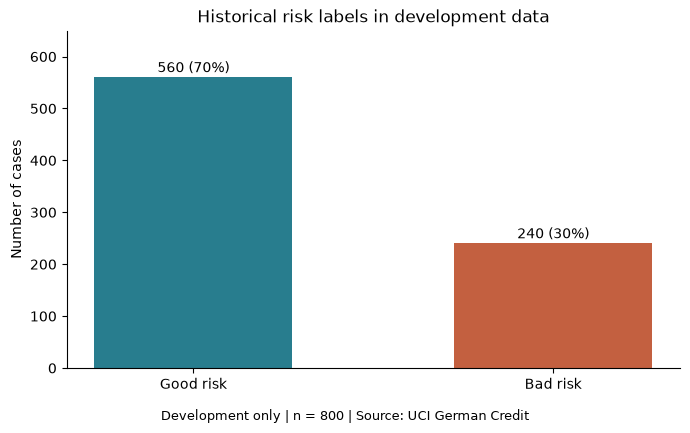

In [4]:
class_counts = y_development.value_counts().reindex([0, 1])
class_summary = pd.DataFrame({
    "label": ["Good risk", "Bad risk"],
    "count": class_counts.to_numpy(),
    "share_percent": class_counts.to_numpy() / len(development) * 100,
}, index=pd.Index([0, 1], name=TARGET))
display(class_summary)
fig, ax = plt.subplots(figsize=(7, 4.3))
bars = ax.bar(class_summary["label"], class_summary["count"], color=[GOOD_COLOR, BAD_COLOR], width=0.55)
for bar, count in zip(bars, class_summary["count"]):
    ax.text(bar.get_x() + bar.get_width()/2, count + 10,
            f"{count} ({count/len(development):.0%})", ha="center")
ax.set(title="Historical risk labels in development data", ylabel="Number of cases", ylim=(0, 650))
fig.text(0.5, 0.01, "Development only | n = 800 | Source: UCI German Credit", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_figure(fig, "development_class_balance.png")
plt.show()


## 5. Examine the two numeric inputs

Histograms show how values are distributed. Boxplots compare the two historical risk groups: the central line is the median, the box is the middle 50%, and dots mark values beyond the usual whiskers. Such dots are not automatically errors.

Amounts stay in their historical DM context. These summaries describe development data; do not use the test cases to extend observed ranges or decide how to transform features.

,count,mean,std,min,25%,50%,75%,max
credit_amount,800.0,3189.59,2673.55,276.0,1353.0,2317.0,3933.0,15945.0
duration_months,800.0,20.77,11.82,4.0,12.0,18.0,24.0,60.0


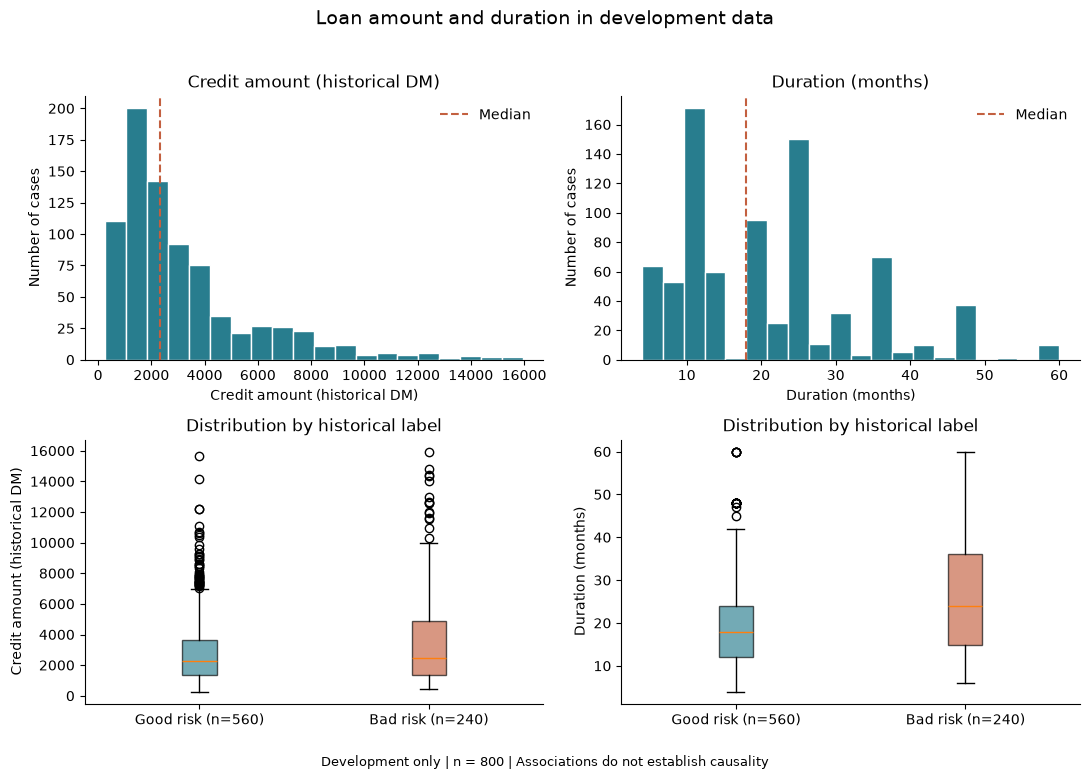

In [5]:
numeric_summary = X_development[NUMERIC_FEATURES].describe().T.round(2)
display(numeric_summary)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.8))
for column, feature in enumerate(NUMERIC_FEATURES):
    values = X_development[feature]
    axes[0, column].hist(values, bins=20, color=GOOD_COLOR, edgecolor="white")
    axes[0, column].axvline(values.median(), color=BAD_COLOR, linestyle="--", label="Median")
    axes[0, column].set(title=FEATURE_TITLES[feature], xlabel=FEATURE_TITLES[feature], ylabel="Number of cases")
    axes[0, column].legend(frameon=False)
    boxes = axes[1, column].boxplot(
        [development.loc[y_development.eq(label), feature] for label in [0, 1]],
        tick_labels=["Good risk (n=560)", "Bad risk (n=240)"], patch_artist=True,
    )
    for patch, color in zip(boxes["boxes"], [GOOD_COLOR, BAD_COLOR]):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    axes[1, column].set(ylabel=FEATURE_TITLES[feature], title="Distribution by historical label")
fig.suptitle("Loan amount and duration in development data", fontsize=14)
fig.text(0.5, 0.01, "Development only | n = 800 | Associations do not establish causality", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
save_figure(fig, "development_numeric_distributions.png")
plt.show()


The credit amount distribution has a long upper tail: its mean is above its median. Keep large values unless there is evidence of a data error. Amount and duration also use different scales; any scaling for logistic regression will be fitted inside training folds later, not here. Differences between the boxplots do not establish predictive performance or a causal effect.

## 6. Understand the five categorical inputs

Bars show counts and each category's share of the 800 development cases. English labels preserve the source definitions. Code numbers are identifiers, not ordered risk scores.

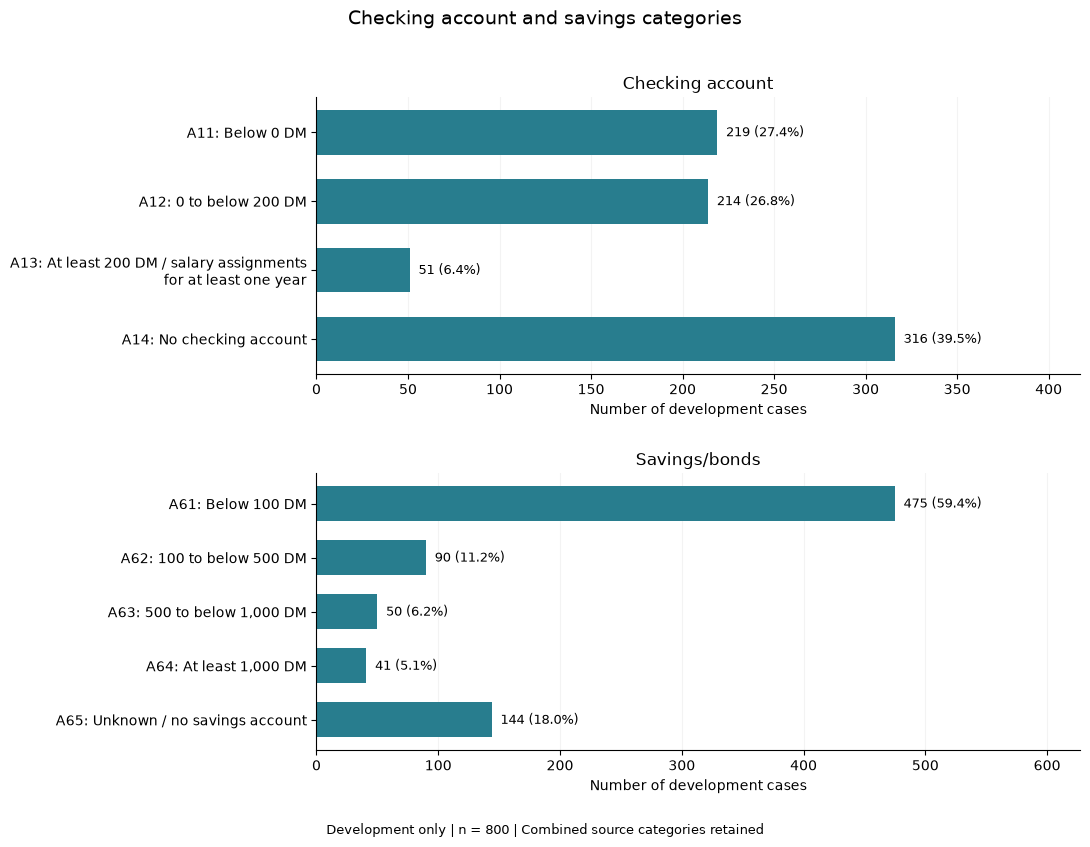

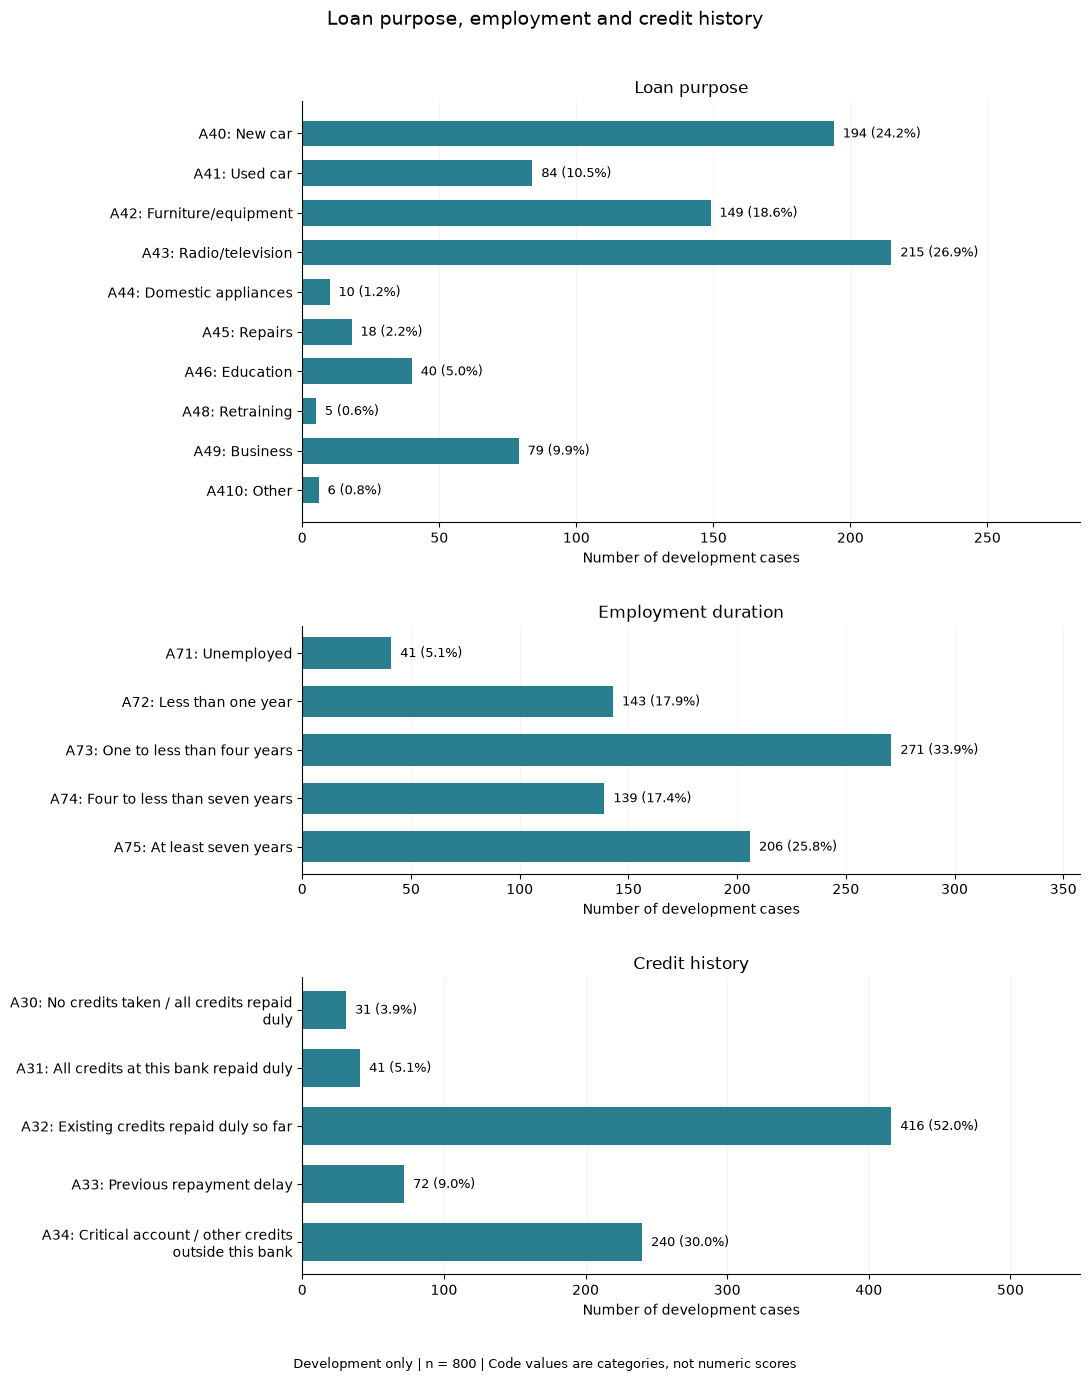

In [6]:
def plot_category_counts(ax, feature):
    labels = CATEGORY_LABELS[feature]
    counts = X_development[feature].value_counts().reindex(labels, fill_value=0)
    names = [fill(f"{code}: {labels[code]}", width=43) for code in counts.index]
    ax.barh(range(len(counts)), counts.to_numpy(), color=GOOD_COLOR, height=0.65)
    ax.set_yticks(range(len(counts)), names)
    ax.invert_yaxis()
    maximum = int(counts.max())
    for row, count in enumerate(counts):
        ax.text(count + maximum*0.015, row, f"{count} ({count/len(development):.1%})", va="center", fontsize=9)
    ax.set(title=FEATURE_TITLES[feature], xlabel="Number of development cases", xlim=(0, maximum*1.32))
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

fig, axes = plt.subplots(2, 1, figsize=(11, 8.5))
for ax, feature in zip(axes, ["checking_status", "savings_status"]):
    plot_category_counts(ax, feature)
fig.suptitle("Checking account and savings categories", fontsize=14)
fig.text(0.5, 0.01, "Development only | n = 800 | Combined source categories retained", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.96), h_pad=2.5)
save_figure(fig, "development_account_categories.png")
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(11, 14), gridspec_kw={"height_ratios": [1.7, 1, 1.2]})
for ax, feature in zip(axes, ["purpose", "employment_duration", "credit_history"]):
    plot_category_counts(ax, feature)
fig.suptitle("Loan purpose, employment and credit history", fontsize=14)
fig.text(0.5, 0.01, "Development only | n = 800 | Code values are categories, not numeric scores", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.035, 1, 0.965), h_pad=2.8)
save_figure(fig, "development_background_categories.png")
plt.show()


## 7. Inspect descriptive label associations

For each category, show the number of cases alongside its observed bad-risk share. This is a sample proportion from development data, not an applicant's predicted default probability. Groups with fewer than 20 cases are flagged as small; 20 is a readability flag, not a statistical reliability threshold. Even larger groups can be uncertain.

Use these tables to understand the dataset, not to write approval rules or choose features based on held-out test results.

In [7]:
category_summaries = {}
for feature, labels in CATEGORY_LABELS.items():
    summary = development.groupby(feature, observed=True)[TARGET].agg(
        count="size", bad_risk_cases="sum", bad_risk_share="mean",
    )
    summary = summary.reindex([code for code in labels if code in summary.index])
    summary.insert(0, "description", [labels[code] for code in summary.index])
    summary["bad_risk_percent"] = (summary.pop("bad_risk_share") * 100).round(1)
    summary["small_group_below_20"] = summary["count"].lt(20)
    category_summaries[feature] = summary
    display(Markdown(f"### {FEATURE_TITLES[feature]}"))
    display(summary)

rare_groups = pd.concat([
    summary.loc[summary["small_group_below_20"]].assign(feature=feature).reset_index()
    .rename(columns={feature: "code"})
    for feature, summary in category_summaries.items()
], ignore_index=True)
display(Markdown("### Small development groups to interpret cautiously"))
display(rare_groups[["feature", "code", "description", "count", "bad_risk_cases", "bad_risk_percent"]])


### Loan purpose

,description,count,bad_risk_cases,bad_risk_percent,small_group_below_20
purpose,,,,,
A40,New car,194,70,36.1,False
A41,Used car,84,16,19.0,False
A42,Furniture/equipment,149,49,32.9,False
A43,Radio/television,215,46,21.4,False
A44,Domestic appliances,10,3,30.0,True
A45,Repairs,18,7,38.9,True
A46,Education,40,20,50.0,False
A48,Retraining,5,1,20.0,True
A49,Business,79,26,32.9,False


### Checking account

,description,count,bad_risk_cases,bad_risk_percent,small_group_below_20
checking_status,,,,,
A11,Below 0 DM,219,105,47.9,False
A12,0 to below 200 DM,214,84,39.3,False
A13,At least 200 DM / salary assignments for at le...,51,13,25.5,False
A14,No checking account,316,38,12.0,False


### Savings/bonds

...

,description,count,bad_risk_cases,bad_risk_percent,small_group_below_20
employment_duration,,,,,
A71,Unemployed,41,17,41.5,False
A72,Less than one year,143,63,44.1,False
A73,One to less than four years,271,75,27.7,False
A74,Four to less than seven years,139,31,22.3,False
A75,At least seven years,206,54,26.2,False


### Credit history

,description,count,bad_risk_cases,bad_risk_percent,small_group_below_20
credit_history,,,,,
A30,No credits taken / all credits repaid duly,31,19,61.3,False
A31,All credits at this bank repaid duly,41,22,53.7,False
A32,Existing credits repaid duly so far,416,134,32.2,False
A33,Previous repayment delay,72,23,31.9,False
A34,Critical account / other credits outside this ...,240,42,17.5,False


### Small development groups to interpret cautiously

,feature,code,description,count,bad_risk_cases,bad_risk_percent
0,purpose,A44,Domestic appliances,10,3,30.0
1,purpose,A45,Repairs,18,7,38.9
2,purpose,A48,Retraining,5,1,20.0
3,purpose,A410,Other,6,2,33.3


Categories differ in their observed bad-risk shares, but this alone does not show how well a model will work on new cases. Several loan-purpose groups are small, so one or two cases can change their percentages substantially. Credit-history wording combines different situations; do not assume the codes form a ranking from safe to risky.

## 8. Save a traceable descriptive summary

The JSON summary records the source and split checksums, package versions, development-only statistics and category tables. The four exported figures can be reused in the report and presentation. None is a model evaluation result.

In [8]:
summary_export = {
    "analysis": "Development data exploration only; no fitted models or test performance",
    "partition": "development",
    "source_sha256": SOURCE_SHA256,
    "split_sha256": sha256(SPLIT_PATH.read_bytes()).hexdigest(),
    "random_seed": 42,
    "rows": int(len(development)),
    "feature_columns": FEATURE_COLUMNS,
    "target": {"name": TARGET, "labels": {"0": "good risk", "1": "bad risk"}},
    "package_versions": {name: version(name) for name in ["pandas", "numpy", "matplotlib", "scikit-learn"]},
    "quality_checks": quality_checks,
    "class_summary": class_summary.reset_index().to_dict(orient="records"),
    "numeric_summary": numeric_summary.to_dict(orient="index"),
    "category_summaries": {
        feature: summary.rename_axis("code").reset_index().to_dict(orient="records")
        for feature, summary in category_summaries.items()
    },
}
(RESULTS_DIR / "development_summary.json").write_text(
    json.dumps(summary_export, indent=2, allow_nan=False) + "\n", encoding="utf-8",
)
print("Saved four development figures and results/development_summary.json.")


Saved four development figures and results/development_summary.json.


## 9. Findings and next steps

- The development partition contains 560 good-risk and 240 bad-risk cases. Accuracy alone would hide the weak bad-risk recall of an always-good predictor.
- No empty input values or duplicate seven-feature profiles were found. Combined unknown categories remain valid inputs.
- Credit amounts have a long upper tail. Keep observations intact and learn any scaling within training folds.
- Some loan-purpose categories contain very few cases; their label proportions need cautious interpretation.
- The seven selected inputs consist of two numeric and five categorical features. Plan category encoding and numeric scaling in a shared pipeline, fitted separately within each training fold.
- Historical DM values, combined source categories and a small sample limit interpretation. These observations do not prove fairness, causality or real-world suitability.

**Next:** implement the preprocessing pipeline, then compare the agreed baseline and models in notebook 02 using cross-validation on development data. Keep `data/split.json` unchanged and leave test performance untouched until the final approach is frozen.